#Data Preparation
### Proyecto BIODIVERSITY-GUARD-Predict (Hito 2)

Parte de dataset_alertas_COMPLETO.csv y dataset_semanal_COMPLETO.csv (ya validados en el EDA). Aplica las 5 subcategorías de Data Preparation: Collecting, Cleaning, Transformation, Reduction, Integration.

## 1. Data Collecting

Ya resuelto en los Notebooks 01-07 (DETER, BDQueimadas, SISAM, NASA POWER). Aquí solo se cargan los datasets finales como punto de partida; no se vuelve a extraer de las fuentes originales.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)

In [ ]:
df_alertas = pd.read_csv("dataset_alertas_COMPLETO.csv")
df_semanal = pd.read_csv("dataset_semanal_COMPLETO.csv")

df_alertas["view_date"] = pd.to_datetime(df_alertas["view_date"])
df_semanal["semana"] = pd.to_datetime(df_semanal["semana"])

print("dataset_alertas:", df_alertas.shape)
print("dataset_semanal:", df_semanal.shape)

print("\nNivel_Riesgo_Amenaza:")
print(df_alertas["Nivel_Riesgo_Amenaza"].value_counts())

print("\narea_ha_total describe:")
print(df_semanal["area_ha_total"].describe())

dataset_alertas: (49971, 33)
dataset_semanal: (11445, 21)

Nivel_Riesgo_Amenaza:
Nivel_Riesgo_Amenaza
Moderado    32440
Alto         7743
Bajo         6483
Crítico      3305
Name: count, dtype: int64

area_ha_total describe:
count    11445.000000
mean       291.371357
std       1219.044315
min          0.010000
25%         16.140000
50%         45.020000
75%        163.380000
max      55192.060000
Name: area_ha_total, dtype: float64


In [ ]:
centroides_municipio = df_alertas.groupby(["municipio_norm", "uf"])[["lat", "lon"]].mean().reset_index()

df_semanal = df_semanal.merge(centroides_municipio, on=["municipio_norm", "uf"], how="left")

print("dataset_semanal con lat/lon:", df_semanal.shape)
print("Nulos en lat/lon:", df_semanal[["lat", "lon"]].isnull().sum().sum())

dataset_semanal con lat/lon: (11445, 23)
Nulos en lat/lon: 0


## 2. Data Cleaning

- Tratamiento de valores atípicos (criterio IQR, ya justificado en el EDA por la prueba de normalidad)
- Decisión sobre el caso Manaus (outlier aislado detectado en el EDA)
- Imputación de valores faltantes (variables climáticas de BDQueimadas, ~18-32% de nulos)

### 2.1. Verificación de outlier puntual: caso Manaus

En el EDA se identificó una alerta con área extrema (19,849.76 ha, Manaus, 2022-10-04). Se verificó contra fuentes externas (INPE/prensa) que octubre de 2022 fue el mes de mayor deforestación histórica registrada en la Amazonía hasta esa fecha, coincidente con la transición política Bolsonaro-Lula. Se confirma como evento real: la alerta se conserva y se trata junto con el resto de valores atípicos mediante IQR (ver 2.2).

In [ ]:
print("Alertas de Manaus en el dataset:", (df_alertas["municipio_norm"] == "MANAUS").sum())
print(df_alertas[df_alertas["municipio_norm"] == "MANAUS"][["id_alerta", "classname", "view_date", "area_ha"]])

Alertas de Manaus en el dataset: 46
       id_alerta             classname  view_date   area_ha
1309        4567       DESMATAMENTO_CR 2022-04-23      9.11
9527       42930       DESMATAMENTO_CR 2022-09-11     11.32
11556      40400       DESMATAMENTO_CR 2022-10-04     27.26
11595      43814            DEGRADACAO 2022-10-04  19849.76
11602      47791            DEGRADACAO 2022-10-04   1044.71
11624       8354       DESMATAMENTO_CR 2022-10-04     13.70
11630      19770       DESMATAMENTO_CR 2022-10-04     15.46
11633      17577            DEGRADACAO 2022-10-04     22.27
11640      38832       DESMATAMENTO_CR 2022-10-04      6.96
11644      36609       DESMATAMENTO_CR 2022-10-04     15.15
11656      27903       DESMATAMENTO_CR 2022-10-04     17.00
11665       3966            DEGRADACAO 2022-10-04     11.93
11677      11316       DESMATAMENTO_CR 2022-10-04      9.18
11679      30384       DESMATAMENTO_CR 2022-10-04     39.62
11681      22831       DESMATAMENTO_CR 2022-10-04     15.98
1202

### 2.2. Tratamiento de valores atípicos (IQR)

Criterio: `[Q1 - 1.5×IQR, Q3 + 1.5×IQR]`, justificado por la prueba de normalidad del EDA (ninguna variable resultó normal).

**Decisión diferenciada:**
- **Variables objetivo** (`area_ha`, `area_ha_total`): NO se capan — ya se confirmó que sus extremos corresponden a eventos reales documentados (temporada de incendios 2024, transición política oct-2022). Se tratan únicamente con transformación logarítmica (sección 3).
- **Variables predictoras**: SÍ se capan (winsorización) al límite superior/inferior de IQR, para reducir el peso desproporcionado de valores extremos sin eliminar la observación completa.

In [ ]:
cols_numericas_alertas = ["area_ha", "areauckm", "num_incendios_7d_previo", "frp_total_7d_previo",
                           "precipitacion_promedio_7d_previo", "dias_sin_lluvia_promedio_7d_previo",
                           "riesgo_fuego_promedio_7d_previo", "pm10_reanalise_7d_previo",
                           "pm2_5_reanalise_7d_previo", "o3_reanalise_7d_previo", "no2_reanalise_7d_previo",
                           "co_reanalise_7d_previo", "so2_reanalise_7d_previo",
                           "T2M_7d_previo", "RH2M_7d_previo", "WS2M_7d_previo"]

cols_numericas_semanal = ["area_ha_total", "num_alertas", "num_incendios", "frp_total", "frp_promedio",
                           "precipitacion_promedio", "dias_sin_lluvia_promedio", "riesgo_fuego_promedio",
                           "pm10_reanalise", "pm2_5_reanalise", "o3_reanalise", "no2_reanalise",
                           "co_reanalise", "so2_reanalise", "T2M", "RH2M", "WS2M"]

print(len(cols_numericas_alertas), len(cols_numericas_semanal))

16 17


In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

cols_predictoras_alertas = [c for c in cols_numericas_alertas if c not in ["area_ha", "areauckm"]]
cols_predictoras_semanal = [c for c in cols_numericas_semanal if c != "area_ha_total"]

resumen_iqr = []
for col in cols_predictoras_alertas:
    lo, hi = limites_iqr(df_alertas[col])
    n_outliers = ((df_alertas[col] < lo) | (df_alertas[col] > hi)).sum()
    resumen_iqr.append({"variable": col, "limite_inf": round(lo,2), "limite_sup": round(hi,2),
                         "n_outliers": n_outliers, "pct": round(n_outliers/len(df_alertas)*100,2)})
print("Total de variables predictoras alertas:", len(cols_predictoras_alertas))
pd.DataFrame(resumen_iqr)

Total de variables predictoras alertas: 14


,variable,limite_inf,limite_sup,n_outliers,pct
0,num_incendios_7d_previo,-95.50,164.50,6578,13.16
1,frp_total_7d_previo,-5033.25,8463.95,7710,15.43
2,precipitacion_promedio_7d_previo,-2.35,3.92,4793,9.59
3,dias_sin_lluvia_promedio_7d_previo,-16.86,33.44,5623,11.25
4,riesgo_fuego_promedio_7d_previo,-0.72,1.87,0,0.00
5,pm10_reanalise_7d_previo,-59.52,142.56,6292,12.59
6,pm2_5_reanalise_7d_previo,-43.01,103.09,6309,12.63
7,o3_reanalise_7d_previo,-13.69,72.38,1085,2.17
8,no2_reanalise_7d_previo,-3.73,7.28,5682,11.37
9,co_reanalise_7d_previo,-0.26,0.81,6109,12.23


In [ ]:
resumen_iqr_semanal = []
for col in cols_predictoras_semanal:
    lo, hi = limites_iqr(df_semanal[col])
    n_outliers = ((df_semanal[col] < lo) | (df_semanal[col] > hi)).sum()
    resumen_iqr_semanal.append({"variable": col, "limite_inf": round(lo,2), "limite_sup": round(hi,2),
                                  "n_outliers": n_outliers, "pct": round(n_outliers/len(df_semanal)*100,2)})
print("Total de variables predictoras semanal:", len(cols_predictoras_semanal))
pd.DataFrame(resumen_iqr_semanal)

Total de variables predictoras semanal: 16


,variable,limite_inf,limite_sup,n_outliers,pct
0,num_alertas,-3.50,8.50,1230,10.75
1,num_incendios,-21.00,35.00,1473,12.87
2,frp_total,-818.55,1364.25,1762,15.40
3,frp_promedio,-58.95,98.24,500,4.37
4,precipitacion_promedio,-1.59,2.65,1172,10.24
5,dias_sin_lluvia_promedio,-13.10,27.16,990,8.65
6,riesgo_fuego_promedio,-0.95,1.93,0,0.00
7,pm10_reanalise,-28.05,84.26,1103,9.64
8,pm2_5_reanalise,-20.38,60.95,1104,9.65
9,o3_reanalise,-11.39,64.02,180,1.57


In [ ]:
df_alertas_capped = df_alertas.copy()
for col in cols_predictoras_alertas:
    lo, hi = limites_iqr(df_alertas[col])
    df_alertas_capped[col] = df_alertas[col].clip(lower=lo, upper=hi)

df_semanal_capped = df_semanal.copy()
for col in cols_predictoras_semanal:
    lo, hi = limites_iqr(df_semanal[col])
    df_semanal_capped[col] = df_semanal[col].clip(lower=lo, upper=hi)

# verificación: los targets NO deben cambiar
print("area_ha sin modificar:", (df_alertas_capped["area_ha"] == df_alertas["area_ha"]).all())
print("area_ha_total sin modificar:", (df_semanal_capped["area_ha_total"] == df_semanal["area_ha_total"]).all())

# verificación: areauckm tampoco debe cambiar (se excluyó de la inputación)
print("areauckm sin modificar:", (df_alertas_capped["areauckm"] == df_alertas["areauckm"]).all())

print("\nShapes finales:", df_alertas_capped.shape, df_semanal_capped.shape)

area_ha sin modificar: True
area_ha_total sin modificar: True
areauckm sin modificar: True

Shapes finales: (49971, 33) (11445, 23)


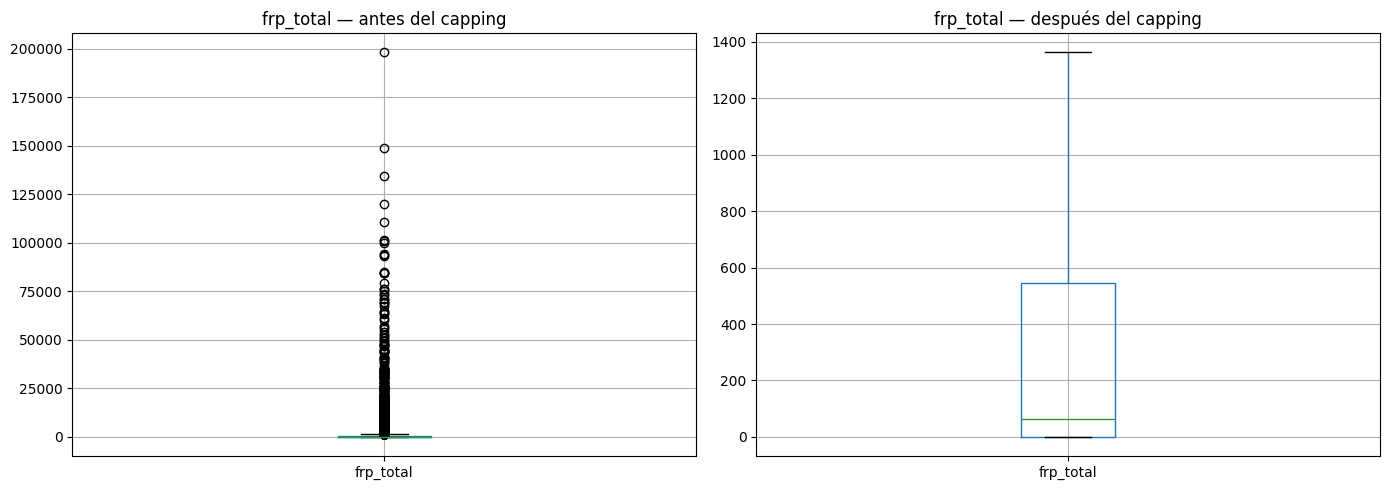

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_semanal[["frp_total"]].boxplot(ax=axes[0])
axes[0].set_title("frp_total — antes del capping")

df_semanal_capped[["frp_total"]].boxplot(ax=axes[1])
axes[1].set_title("frp_total — después del capping")

plt.tight_layout()
plt.show()

**Resumen: Data Cleaning completado**

- Outlier de Manaus verificado contra fuentes externas → conservado (evento real).
- `areauckm` excluida del tratamiento IQR (distribución degenerada por ceros estructurales).
- Capping IQR aplicado a 14 variables predictoras en `dataset_alertas` y 16 en `dataset_semanal`, con rango de outliers detectados entre 0% y 15.43%.
- Variables objetivo (`area_ha`, `area_ha_total`) conservadas sin modificar — su tratamiento es vía transformación  (sección 3).



### 2.3. Imputación de valores faltantes

Afecta solo a `precipitacion_promedio`, `dias_sin_lluvia_promedio` y `riesgo_fuego_promedio` (y sus versiones `_7d_previo`), con nulos porque BDQueimadas solo reporta clima cuando detecta un foco de calor.

**Estrategia:** imputación por mediana, agrupada por `municipio_norm` (clima local), con opción de inputar a la mediana global si el municipio no tiene ningún dato disponible. Se añade además una bandera binaria `sin_foco_detectado` para no perder la información de que esa fila originalmente no tenía lectura climática de BDQueimadas.

In [ ]:
cols_bdqueimadas_alertas = ["precipitacion_promedio_7d_previo", "dias_sin_lluvia_promedio_7d_previo",
                             "riesgo_fuego_promedio_7d_previo"]
cols_bdqueimadas_semanal = ["precipitacion_promedio", "dias_sin_lluvia_promedio", "riesgo_fuego_promedio"]

def imputar_mediana_por_municipio(df, cols):
    df = df.copy()
    for col in cols:
        df[f"{col}_sin_foco"] = df[col].isna().astype(int)
        mediana_municipio = df.groupby("municipio_norm")[col].transform("median")
        df[col] = df[col].fillna(mediana_municipio)
        df[col] = df[col].fillna(df[col].median())  # inputacion a la mediana global si el municipio no tiene datos
    return df

df_alertas_capped = imputar_mediana_por_municipio(df_alertas_capped, cols_bdqueimadas_alertas)
df_semanal_capped = imputar_mediana_por_municipio(df_semanal_capped, cols_bdqueimadas_semanal)

print("Nulos restantes en alertas:", df_alertas_capped[cols_bdqueimadas_alertas].isnull().sum().sum())
print("Nulos restantes en semanal:", df_semanal_capped[cols_bdqueimadas_semanal].isnull().sum().sum())

Nulos restantes en alertas: 0
Nulos restantes en semanal: 0


## 3. Data Transformation

**Reglas aplicadas (resumen):**

| | log1p | StandardScaler |
|---|---|---|
| Target (`area_ha`, `area_ha_total`) | Sí | No — se deja en escala interpretable (hectáreas tras `expm1()`), para que las métricas de error (MAE, RMSE) sean comparables directamente contra los criterios de éxito definidos en Business Understanding |
| Predictoras sesgadas (cola larga) | Sí | Sí, aplicado después del log |
| Predictoras no sesgadas | No | Sí |



**Reglas:**
- Target (`area_ha`, `area_ha_total`): solo `log1p`, sin escalar (para mantener las métricas de error en unidades interpretables).
- Predictoras con sesgo relevante (|skewness| > 1): `log1p` + `StandardScaler`.
- Predictoras sin sesgo relevante: solo `StandardScaler`.

In [ ]:
features_excluidas_alertas = ["id_alerta", "gid", "classname", "view_date", "publish_month",
                               "sensor", "satellite", "municipality", "mun_geocod", "uf",
                               "area_ha", "areauckm", "dentro_area_protegida", "uc",
                               "municipio_norm", "Nivel_Riesgo_Amenaza", "score_riesgo"]
features_alertas = [c for c in df_alertas_capped.columns if c not in features_excluidas_alertas]

features_excluidas_semanal = ["semana", "municipio_norm", "uf", "area_ha_total", "score_riesgo_promedio", "num_alertas"]
features_semanal = [c for c in df_semanal_capped.columns if c not in features_excluidas_semanal]

print("Features Frente 2:", features_alertas)
print("Features Frente 1:", features_semanal)

Features Frente 2: ['lat', 'lon', 'num_incendios_7d_previo', 'frp_total_7d_previo', 'precipitacion_promedio_7d_previo', 'dias_sin_lluvia_promedio_7d_previo', 'riesgo_fuego_promedio_7d_previo', 'pm10_reanalise_7d_previo', 'pm2_5_reanalise_7d_previo', 'o3_reanalise_7d_previo', 'no2_reanalise_7d_previo', 'co_reanalise_7d_previo', 'so2_reanalise_7d_previo', 'T2M_7d_previo', 'RH2M_7d_previo', 'WS2M_7d_previo', 'precipitacion_promedio_7d_previo_sin_foco', 'dias_sin_lluvia_promedio_7d_previo_sin_foco', 'riesgo_fuego_promedio_7d_previo_sin_foco']
Features Frente 1: ['num_incendios', 'frp_total', 'frp_promedio', 'precipitacion_promedio', 'dias_sin_lluvia_promedio', 'riesgo_fuego_promedio', 'pm10_reanalise', 'pm2_5_reanalise', 'o3_reanalise', 'no2_reanalise', 'co_reanalise', 'so2_reanalise', 'T2M', 'RH2M', 'WS2M', 'lat', 'lon', 'precipitacion_promedio_sin_foco', 'dias_sin_lluvia_promedio_sin_foco', 'riesgo_fuego_promedio_sin_foco']


Skewness sobre las listas definitivas

In [ ]:
skew_alertas = df_alertas_capped[features_alertas].skew().sort_values(ascending=False)
skew_semanal = df_semanal_capped[features_semanal].skew().sort_values(ascending=False)

print("Skewness - Frente 2:")
print(skew_alertas)
print("\nSkewness - Frente 1:")
print(skew_semanal)

Skewness - Frente 2:
precipitacion_promedio_7d_previo_sin_foco      1.662868
dias_sin_lluvia_promedio_7d_previo_sin_foco    1.660757
riesgo_fuego_promedio_7d_previo_sin_foco       1.654969
precipitacion_promedio_7d_previo               1.448431
dias_sin_lluvia_promedio_7d_previo             1.345099
num_incendios_7d_previo                        1.217054
frp_total_7d_previo                            1.200913
no2_reanalise_7d_previo                        1.193265
so2_reanalise_7d_previo                        1.167493
pm10_reanalise_7d_previo                       1.142958
pm2_5_reanalise_7d_previo                      1.140968
co_reanalise_7d_previo                         1.135010
WS2M_7d_previo                                 0.975418
o3_reanalise_7d_previo                         0.736830
lat                                            0.543191
RH2M_7d_previo                                -0.104248
riesgo_fuego_promedio_7d_previo               -0.143821
T2M_7d_previo              

### Clasificación para Data Transformation (umbral |skew| > 1)

**Frente 2 — llevan log1p + StandardScaler:**
`precipitacion_promedio_7d_previo`, `dias_sin_lluvia_promedio_7d_previo`, `num_incendios_7d_previo`, `frp_total_7d_previo`, `no2_reanalise_7d_previo`, `so2_reanalise_7d_previo`, `pm10_reanalise_7d_previo`, `pm2_5_reanalise_7d_previo`, `co_reanalise_7d_previo`

**Frente 2 — solo StandardScaler (sin sesgo relevante):**
`WS2M_7d_previo` (borde, 0.98), `o3_reanalise_7d_previo`, `lat`, `lon`, `RH2M_7d_previo`, `riesgo_fuego_promedio_7d_previo`, `T2M_7d_previo`

**Frente 2 — banderas binarias (`_sin_foco`): no llevan log ni scaler**, se mantienen como 0/1.

**Frente 1 — llevan log1p + StandardScaler:**
`precipitacion_promedio`, `dias_sin_lluvia_promedio`, `num_incendios`, `frp_total`, `pm10_reanalise`, `co_reanalise`, `pm2_5_reanalise`, `so2_reanalise`, `no2_reanalise`, `frp_promedio`, `WS2M`

**Frente 1 — solo StandardScaler:**
`o3_reanalise`, `T2M`, `riesgo_fuego_promedio`, `RH2M`, `lat`, `lon`

**Frente 1 — banderas `_sin_foco`:** no llevan log ni scaler.

In [ ]:
cols_log_alertas = ["precipitacion_promedio_7d_previo", "dias_sin_lluvia_promedio_7d_previo",
                     "num_incendios_7d_previo", "frp_total_7d_previo", "no2_reanalise_7d_previo",
                     "so2_reanalise_7d_previo", "pm10_reanalise_7d_previo", "pm2_5_reanalise_7d_previo",
                     "co_reanalise_7d_previo"]

cols_log_semanal = ["precipitacion_promedio", "dias_sin_lluvia_promedio", "num_incendios", "frp_total",
                     "pm10_reanalise", "co_reanalise", "pm2_5_reanalise", "so2_reanalise",
                     "no2_reanalise", "frp_promedio", "WS2M"]

df_alertas_transf = df_alertas_capped.copy()
df_semanal_transf = df_semanal_capped.copy()

for col in cols_log_alertas:
    df_alertas_transf[col] = np.log1p(df_alertas_transf[col])

for col in cols_log_semanal:
    df_semanal_transf[col] = np.log1p(df_semanal_transf[col])

df_alertas_transf["area_ha_log"] = np.log1p(df_alertas_transf["area_ha"])
df_semanal_transf["area_ha_total_log"] = np.log1p(df_semanal_transf["area_ha_total"])

print("Transformación log aplicada. Verificando skewness tras el cambio:")
print(df_alertas_transf[cols_log_alertas].skew())
print(df_semanal_transf[cols_log_semanal].skew())

Transformación log aplicada. Verificando skewness tras el cambio:
precipitacion_promedio_7d_previo      0.995715
dias_sin_lluvia_promedio_7d_previo    0.240240
num_incendios_7d_previo              -0.065563
frp_total_7d_previo                  -0.591225
no2_reanalise_7d_previo               0.548566
so2_reanalise_7d_previo               0.769736
pm10_reanalise_7d_previo              0.227293
pm2_5_reanalise_7d_previo             0.226050
co_reanalise_7d_previo                0.970169
dtype: float64
precipitacion_promedio      1.369986
dias_sin_lluvia_promedio    0.103300
num_incendios               0.263464
frp_total                  -0.181700
pm10_reanalise              0.375164
co_reanalise                1.042113
pm2_5_reanalise             0.361080
so2_reanalise               0.797059
no2_reanalise               0.557950
frp_promedio               -0.451457
WS2M                        0.906577
dtype: float64


### Hallazgo: asimetría residual en precipitación

Tras la transformación logarítmica, `precipitacion_promedio` (Frente 1) mantiene asimetría moderada (1.37, vs. 1.70 original). Esto se explica por la alta concentración de valores en cero (ausencia de lluvia en una proporción considerable de semanas-municipio, ya documentada en el EDA), sobre los cuales `log1p` no tiene efecto de corrección. Se acepta esta limitación dado que refleja la naturaleza real del fenómeno climático, sin intervención adicional.

### Estandarización (StandardScaler)

Se aplica a todas las variables predictoras numéricas continuas (ya con la transformación logarítmica donde correspondía), excluyendo las banderas binarias `_sin_foco`, que se mantienen en 0/1.

In [ ]:
from sklearn.preprocessing import StandardScaler

cols_banderas_alertas = ["precipitacion_promedio_7d_previo_sin_foco",
                          "dias_sin_lluvia_promedio_7d_previo_sin_foco",
                          "riesgo_fuego_promedio_7d_previo_sin_foco"]

cols_escalar_alertas = [c for c in features_alertas if c not in cols_banderas_alertas]

scaler_alertas = StandardScaler()
df_alertas_transf[cols_escalar_alertas] = scaler_alertas.fit_transform(df_alertas_transf[cols_escalar_alertas])

print("Variables escaladas (Frente 2):", len(cols_escalar_alertas))
df_alertas_transf[cols_escalar_alertas].describe().loc[["mean", "std"]].round(3)

Variables escaladas (Frente 2): 16


,lat,lon,num_incendios_7d_previo,frp_total_7d_previo,precipitacion_promedio_7d_previo,dias_sin_lluvia_promedio_7d_previo,riesgo_fuego_promedio_7d_previo,pm10_reanalise_7d_previo,pm2_5_reanalise_7d_previo,o3_reanalise_7d_previo,no2_reanalise_7d_previo,co_reanalise_7d_previo,so2_reanalise_7d_previo,T2M_7d_previo,RH2M_7d_previo,WS2M_7d_previo
mean,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
cols_banderas_semanal = ["precipitacion_promedio_sin_foco", "dias_sin_lluvia_promedio_sin_foco",
                          "riesgo_fuego_promedio_sin_foco"]

cols_escalar_semanal = [c for c in features_semanal if c not in cols_banderas_semanal]

scaler_semanal = StandardScaler()
df_semanal_transf[cols_escalar_semanal] = scaler_semanal.fit_transform(df_semanal_transf[cols_escalar_semanal])

print("Variables escaladas (Frente 1):", len(cols_escalar_semanal))
df_semanal_transf[cols_escalar_semanal].describe().loc[["mean", "std"]].round(3)

Variables escaladas (Frente 1): 17


,num_incendios,frp_total,frp_promedio,precipitacion_promedio,dias_sin_lluvia_promedio,riesgo_fuego_promedio,pm10_reanalise,pm2_5_reanalise,o3_reanalise,no2_reanalise,co_reanalise,so2_reanalise,T2M,RH2M,WS2M,lat,lon
mean,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### Nota: variables categóricas y codificación (encoding)

El dataset completo conserva variables categóricas (`classname`, `municipio_norm`, `uf`, `sensor`, `satellite`, `uc`), pero ninguna forma parte del set de variables predictoras final: se excluyeron por generar fuga de información (`classname`, `dentro_area_protegida`, `uc`) o por ser identificadores sin valor predictivo directo (`municipio_norm`, `sensor`, `satellite`). Como resultado, el set de predictoras quedó compuesto en su totalidad por variables numéricas, por lo que no corresponde aplicar codificación (encoding) en esta etapa.

La variable objetivo `Nivel_Riesgo_Amenaza` sigue siendo categórica; su codificación (si el algoritmo de clasificación elegido lo requiere) se aplicará en la etapa de Modelado (Hito 3), no en Data Preparation.

### Resumen: variables predictoras por frente

**Frente 2 (`dataset_alertas`, clasificación) — 19 variables:**
`lat`, `lon`, `num_incendios_7d_previo`, `frp_total_7d_previo`, `precipitacion_promedio_7d_previo`, `dias_sin_lluvia_promedio_7d_previo`, `riesgo_fuego_promedio_7d_previo`, `pm10_reanalise_7d_previo`, `pm2_5_reanalise_7d_previo`, `o3_reanalise_7d_previo`, `no2_reanalise_7d_previo`, `co_reanalise_7d_previo`, `so2_reanalise_7d_previo`, `T2M_7d_previo`, `RH2M_7d_previo`, `WS2M_7d_previo`, `precipitacion_promedio_7d_previo_sin_foco`, `dias_sin_lluvia_promedio_7d_previo_sin_foco`, `riesgo_fuego_promedio_7d_previo_sin_foco`

**Frente 1 (`dataset_semanal`, regresión) — 20 variables:**
`num_incendios`, `frp_total`, `frp_promedio`, `precipitacion_promedio`, `dias_sin_lluvia_promedio`, `riesgo_fuego_promedio`, `pm10_reanalise`, `pm2_5_reanalise`, `o3_reanalise`, `no2_reanalise`, `co_reanalise`, `so2_reanalise`, `T2M`, `RH2M`, `WS2M`, `precipitacion_promedio_sin_foco`, `dias_sin_lluvia_promedio_sin_foco`, `riesgo_fuego_promedio_sin_foco`, `lat`, `lon`

Ambos sets excluyen variables que generarían fuga de información (`classname`, `dentro_area_protegida`, `area_ha`/`area_ha_total`, `score_riesgo`, `num_alertas`) e identificadores sin valor predictivo directo.

## 4. Data Reduction

El EDA (Hito 1) detectó multicolinealidad severa entre variables de SISAM: `pm10_reanalise` y `pm2_5_reanalise` con correlación r=1.00, y ambas correlacionadas con `co_reanalise`, `no2_reanalise` y `so2_reanalise` (r=0.90-0.98). Mantener las 5 juntas en un modelo lineal introduce redundancia severa (inestabilidad en los coeficientes); en modelos de árbol el efecto es menor, pero igual reduce la interpretabilidad.

**Estrategia:** calcular el Factor de Inflación de la Varianza (VIF) sobre el set de variables predictoras ya escaladas, para cuantificar la multicolinealidad de forma objetiva (no solo con la matriz de correlación) y decidir cuáles variables de SISAM conservar.

Frente 2

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calcular_vif(df, columnas):
    X = df[columnas].dropna()
    vif_data = pd.DataFrame()
    vif_data["variable"] = columnas
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(columnas))]
    return vif_data.sort_values("VIF", ascending=False)

cols_vif_alertas = [c for c in features_alertas if "_sin_foco" not in c]
vif_alertas = calcular_vif(df_alertas_transf, cols_vif_alertas)
print(vif_alertas)

                              variable         VIF
7             pm10_reanalise_7d_previo  977.666992
8            pm2_5_reanalise_7d_previo  924.255988
12             so2_reanalise_7d_previo   19.981470
2              num_incendios_7d_previo   16.448100
10             no2_reanalise_7d_previo   15.673603
3                  frp_total_7d_previo   15.568385
11              co_reanalise_7d_previo   14.667800
14                      RH2M_7d_previo    7.892521
13                       T2M_7d_previo    5.636741
9               o3_reanalise_7d_previo    4.418549
6      riesgo_fuego_promedio_7d_previo    2.881324
5   dias_sin_lluvia_promedio_7d_previo    2.754032
1                                  lon    2.088625
0                                  lat    1.979126
4     precipitacion_promedio_7d_previo    1.726803
15                      WS2M_7d_previo    1.100650


Frente 1

In [ ]:
cols_vif_semanal = [c for c in features_semanal if "_sin_foco" not in c]
vif_semanal = calcular_vif(df_semanal_transf, cols_vif_semanal)
print(vif_semanal)

                    variable         VIF
6             pm10_reanalise  508.756710
7            pm2_5_reanalise  465.570934
1                  frp_total  178.834891
0              num_incendios   56.255460
2               frp_promedio   48.869106
10              co_reanalise   11.184708
11             so2_reanalise   10.486301
9              no2_reanalise    8.385765
13                      RH2M    6.473612
12                       T2M    4.636021
8               o3_reanalise    4.484659
5      riesgo_fuego_promedio    2.600807
16                       lon    2.555422
4   dias_sin_lluvia_promedio    2.374267
15                       lat    2.094763
3     precipitacion_promedio    1.586737
14                      WS2M    1.110640


### Iteración 2
Quitando pm10_reanalise (el VIF más alto en ambos frentes)

Frente 2

In [ ]:
cols_vif_alertas_v2 = [c for c in cols_vif_alertas if c != "pm10_reanalise_7d_previo"]
vif_alertas_v2 = calcular_vif(df_alertas_transf, cols_vif_alertas_v2)
print(vif_alertas_v2)

                              variable        VIF
11             so2_reanalise_7d_previo  19.698083
2              num_incendios_7d_previo  16.446033
9              no2_reanalise_7d_previo  15.615805
3                  frp_total_7d_previo  15.434506
10              co_reanalise_7d_previo  14.503793
7            pm2_5_reanalise_7d_previo  12.241433
13                      RH2M_7d_previo   7.741978
12                       T2M_7d_previo   5.389258
8               o3_reanalise_7d_previo   4.415211
6      riesgo_fuego_promedio_7d_previo   2.871098
5   dias_sin_lluvia_promedio_7d_previo   2.750153
1                                  lon   2.064920
0                                  lat   1.892189
4     precipitacion_promedio_7d_previo   1.725946
14                      WS2M_7d_previo   1.100602


Frente 1

In [ ]:
cols_vif_semanal_v2 = [c for c in cols_vif_semanal if c != "pm10_reanalise"]
vif_semanal_v2 = calcular_vif(df_semanal_transf, cols_vif_semanal_v2)
print(vif_semanal_v2)

                    variable         VIF
1                  frp_total  177.973884
0              num_incendios   56.166898
2               frp_promedio   48.714838
9               co_reanalise   10.755976
10             so2_reanalise   10.279357
8              no2_reanalise    8.369378
6            pm2_5_reanalise    7.134299
12                      RH2M    6.362155
7               o3_reanalise    4.470116
11                       T2M    4.431000
5      riesgo_fuego_promedio    2.600695
15                       lon    2.540723
4   dias_sin_lluvia_promedio    2.373944
14                       lat    2.083149
3     precipitacion_promedio    1.585838
13                      WS2M    1.110184


###Iteración 2: quitar el siguiente más alto de cada frente

Frente 2: el más alto ahora es so2_reanalise_7d_previo (19.7)    
Frente 1: el más alto es frp_total (178) — mucho más grave que en Frente 2

Frente 2

In [ ]:
cols_vif_alertas_v3 = [c for c in cols_vif_alertas_v2 if c != "so2_reanalise_7d_previo"]
vif_alertas_v3 = calcular_vif(df_alertas_transf, cols_vif_alertas_v3)
print(vif_alertas_v3)

                              variable        VIF
2              num_incendios_7d_previo  16.441167
3                  frp_total_7d_previo  15.425932
10              co_reanalise_7d_previo  12.788446
7            pm2_5_reanalise_7d_previo  12.066779
12                      RH2M_7d_previo   7.735738
9              no2_reanalise_7d_previo   7.025042
11                       T2M_7d_previo   5.371414
8               o3_reanalise_7d_previo   4.000531
6      riesgo_fuego_promedio_7d_previo   2.870846
5   dias_sin_lluvia_promedio_7d_previo   2.656609
1                                  lon   2.056362
0                                  lat   1.891743
4     precipitacion_promedio_7d_previo   1.725941
13                      WS2M_7d_previo   1.060866


Frente 1

In [ ]:
cols_vif_semanal_v3 = [c for c in cols_vif_semanal_v2 if c != "frp_total"]
vif_semanal_v3 = calcular_vif(df_semanal_transf, cols_vif_semanal_v3)
print(vif_semanal_v3)

                    variable        VIF
8               co_reanalise  10.671362
9              so2_reanalise  10.265283
7              no2_reanalise   8.346940
5            pm2_5_reanalise   7.108547
11                      RH2M   6.351981
0              num_incendios   4.823658
6               o3_reanalise   4.439572
10                       T2M   4.422370
1               frp_promedio   4.080821
4      riesgo_fuego_promedio   2.600192
14                       lon   2.530276
3   dias_sin_lluvia_promedio   2.373517
13                       lat   2.083147
2     precipitacion_promedio   1.584228
12                      WS2M   1.110080


###Iteración 3

Frente 2: el más alto es num_incendios_7d_previo (16.4)

Frente 1: el más alto es co_reanalise (10.7), muy cerca del umbral

Frente 2

In [ ]:
cols_vif_alertas_v4 = [c for c in cols_vif_alertas_v3 if c != "num_incendios_7d_previo"]
vif_alertas_v4 = calcular_vif(df_alertas_transf, cols_vif_alertas_v4)
print(vif_alertas_v4)

                              variable        VIF
9               co_reanalise_7d_previo  12.755733
6            pm2_5_reanalise_7d_previo  12.027932
11                      RH2M_7d_previo   7.731563
8              no2_reanalise_7d_previo   7.024753
10                       T2M_7d_previo   5.369073
7               o3_reanalise_7d_previo   3.998956
5      riesgo_fuego_promedio_7d_previo   2.842833
4   dias_sin_lluvia_promedio_7d_previo   2.636697
2                  frp_total_7d_previo   2.308838
1                                  lon   2.032846
0                                  lat   1.872853
3     precipitacion_promedio_7d_previo   1.700017
12                      WS2M_7d_previo   1.060615


Frente 1

In [ ]:
cols_vif_semanal_v4 = [c for c in cols_vif_semanal_v3 if c != "co_reanalise"]
vif_semanal_v4 = calcular_vif(df_semanal_transf, cols_vif_semanal_v4)
print(vif_semanal_v4)

                    variable       VIF
8              so2_reanalise  9.689915
7              no2_reanalise  8.119020
10                      RH2M  6.341005
0              num_incendios  4.818746
9                        T2M  4.414795
6               o3_reanalise  4.413081
5            pm2_5_reanalise  4.115789
1               frp_promedio  4.077314
4      riesgo_fuego_promedio  2.599273
3   dias_sin_lluvia_promedio  2.367276
13                       lon  2.225993
12                       lat  1.812146
2     precipitacion_promedio  1.583278
11                      WS2M  1.107345


###Iteración 4 — Frente 2

Sacar CO

In [ ]:
cols_vif_alertas_v5 = [c for c in cols_vif_alertas_v4 if c != "co_reanalise_7d_previo"]
vif_alertas_v5 = calcular_vif(df_alertas_transf, cols_vif_alertas_v5)
print(vif_alertas_v5)

                              variable       VIF
10                      RH2M_7d_previo  7.711689
6            pm2_5_reanalise_7d_previo  6.681132
8              no2_reanalise_7d_previo  6.073336
9                        T2M_7d_previo  5.333732
7               o3_reanalise_7d_previo  3.946785
5      riesgo_fuego_promedio_7d_previo  2.840974
4   dias_sin_lluvia_promedio_7d_previo  2.631096
2                  frp_total_7d_previo  2.302564
1                                  lon  1.882659
3     precipitacion_promedio_7d_previo  1.696523
0                                  lat  1.594430
11                      WS2M_7d_previo  1.059973


### Resultado: reducción de multicolinealidad (VIF < 10)

Proceso iterativo de eliminación (umbral VIF < 10), eliminando en cada paso la variable con mayor VIF y recalculando:

**Frente 2:** se eliminaron `pm10_reanalise_7d_previo`, `so2_reanalise_7d_previo`, `num_incendios_7d_previo`, `co_reanalise_7d_previo` (4 variables). Se conservó `pm2_5_reanalise_7d_previo` sobre PM10/CO por ser el estándar más usado en literatura de exposición a humo de biomasa. Quedan 12 variables, todas con VIF < 10.

**Frente 1:** se eliminaron `pm10_reanalise`, `frp_total`, `co_reanalise` (3 variables). Quedan 14 variables (incluyendo `lat`/`lon`), todas con VIF < 10.

La eliminación de variables redundantes no implica pérdida de señal real: la correlación entre las variables eliminadas y las conservadas (r=0.90-1.00, ya documentado en el EDA) garantiza que la información se mantiene, solo que representada por una variable en lugar de varias.

In [ ]:
features_alertas_final = cols_vif_alertas_v5 + ["precipitacion_promedio_7d_previo_sin_foco",
                                                  "dias_sin_lluvia_promedio_7d_previo_sin_foco",
                                                  "riesgo_fuego_promedio_7d_previo_sin_foco"]

features_semanal_final = cols_vif_semanal_v4 + ["precipitacion_promedio_sin_foco",
                                                  "dias_sin_lluvia_promedio_sin_foco",
                                                  "riesgo_fuego_promedio_sin_foco"]

print("Frente 2 — features finales:", len(features_alertas_final))
print(features_alertas_final)
print("\nFrente 1 — features finales:", len(features_semanal_final))
print(features_semanal_final)

Frente 2 — features finales: 15
['lat', 'lon', 'frp_total_7d_previo', 'precipitacion_promedio_7d_previo', 'dias_sin_lluvia_promedio_7d_previo', 'riesgo_fuego_promedio_7d_previo', 'pm2_5_reanalise_7d_previo', 'o3_reanalise_7d_previo', 'no2_reanalise_7d_previo', 'T2M_7d_previo', 'RH2M_7d_previo', 'WS2M_7d_previo', 'precipitacion_promedio_7d_previo_sin_foco', 'dias_sin_lluvia_promedio_7d_previo_sin_foco', 'riesgo_fuego_promedio_7d_previo_sin_foco']

Frente 1 — features finales: 17
['num_incendios', 'frp_promedio', 'precipitacion_promedio', 'dias_sin_lluvia_promedio', 'riesgo_fuego_promedio', 'pm2_5_reanalise', 'o3_reanalise', 'no2_reanalise', 'so2_reanalise', 'T2M', 'RH2M', 'WS2M', 'lat', 'lon', 'precipitacion_promedio_sin_foco', 'dias_sin_lluvia_promedio_sin_foco', 'riesgo_fuego_promedio_sin_foco']


## 5. Data Integration

Verificación final de consistencia entre ambos datasets, y guardado de las versiones listas para la etapa de Modelado (Hito 3): targets transformados, variables predictoras finales (sin multicolinealidad ni fuga de información), outliers tratados, nulos imputados.

In [ ]:
df_alertas_final = df_alertas_transf[["id_alerta", "municipio_norm", "uf", "view_date",
                                        "classname", "area_ha", "area_ha_log",
                                        "Nivel_Riesgo_Amenaza"] + features_alertas_final].copy()

df_semanal_final = df_semanal_transf[["municipio_norm", "uf", "semana",
                                        "area_ha_total", "area_ha_total_log"] + features_semanal_final].copy()

print("dataset_alertas_PREPARADO:", df_alertas_final.shape)
print("dataset_semanal_PREPARADO:", df_semanal_final.shape)

print("\nNulos en df_alertas_final:", df_alertas_final.isnull().sum().sum())
print("Nulos en df_semanal_final:", df_semanal_final.isnull().sum().sum())

df_alertas_final.to_csv("dataset_alertas_PREPARADO.csv", index=False)
df_semanal_final.to_csv("dataset_semanal_PREPARADO.csv", index=False)

print("\nArchivos guardados: dataset_alertas_PREPARADO.csv, dataset_semanal_PREPARADO.csv")

dataset_alertas_PREPARADO: (49971, 23)
dataset_semanal_PREPARADO: (11445, 22)

Nulos en df_alertas_final: 0
Nulos en df_semanal_final: 0

Archivos guardados: dataset_alertas_PREPARADO.csv, dataset_semanal_PREPARADO.csv


In [ ]:
df_alertas_final.shape

(49971, 23)

In [ ]:
df_semanal_final.shape

(11445, 22)